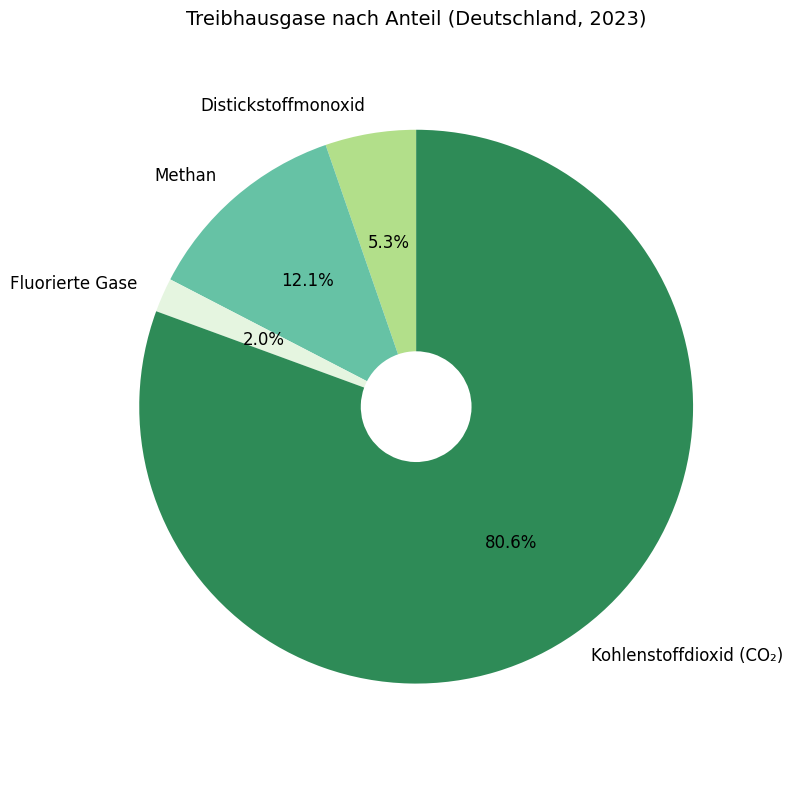

In [9]:
import matplotlib.pyplot as plt


labels = [ 'Distickstoffmonoxid', 'Methan','Fluorierte Gase', 'Kohlenstoffdioxid (CO₂)']
werte = [5.3, 12.1,2.0,  80.6]
farben = [ '#b2df8a', '#66c2a5','#e5f5e0', '#2e8b57']


fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(
    werte,
    labels=labels,
    colors=farben,
    autopct='%1.1f%%',
    startangle=90,
    textprops={'fontsize': 12, 'color': 'black'},
    wedgeprops={'width': 0.8} 
)

ax.axis('equal')
plt.title("Treibhausgase nach Anteil (Deutschland, 2023)", fontsize=14)
plt.tight_layout()
plt.show()


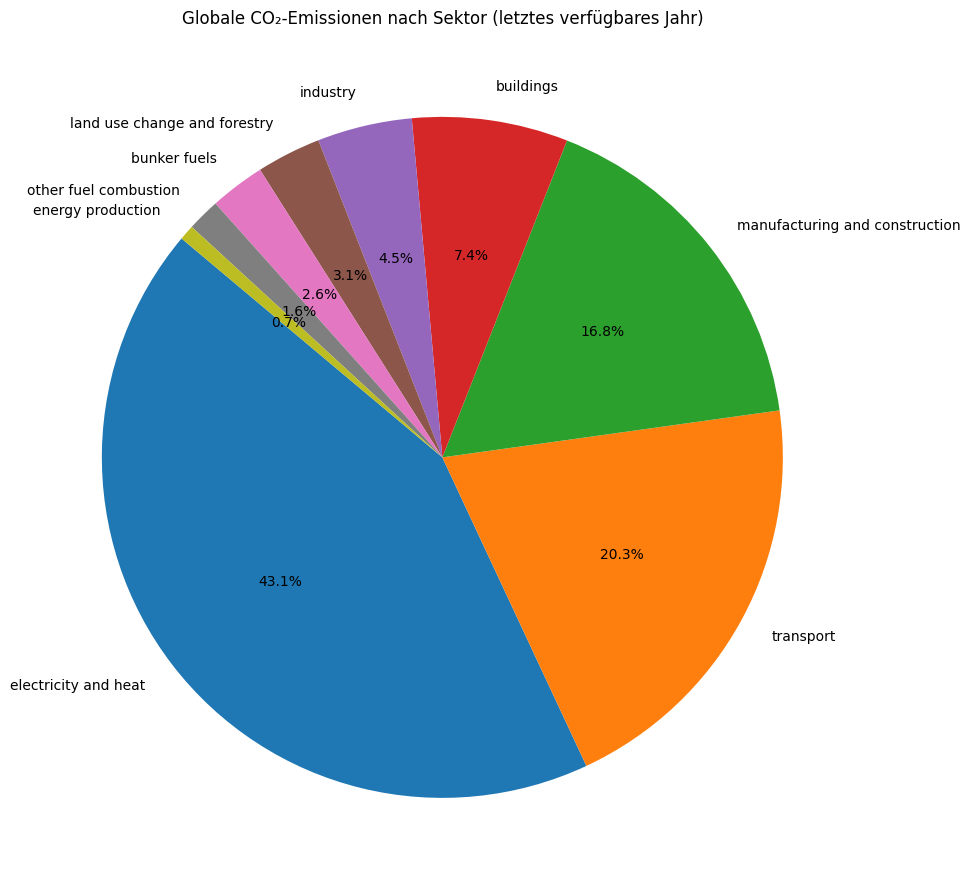

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/co-emissions-by-sector.csv")

emission_cols = [col for col in df.columns if "Carbon dioxide emissions" in col or "Fugitive emissions" in col]


df_global_latest = df[df["Entity"] == "World"].sort_values("Year", ascending=False).head(1)


emissions = df_global_latest[emission_cols].iloc[0].dropna()
emissions = emissions[emissions > 0].sort_values(ascending=False)


labels = emissions.index.str.replace("Carbon dioxide emissions from ", "", regex=False)
labels = labels.str.replace("Fugitive emissions of carbon dioxide from ", "", regex=False)


plt.figure(figsize=(10, 10))
plt.pie(emissions, labels=labels, autopct='%1.1f%%', startangle=140)
plt.title("Globale CO₂-Emissionen nach Sektor (letztes verfügbares Jahr)")
plt.tight_layout()
plt.show()


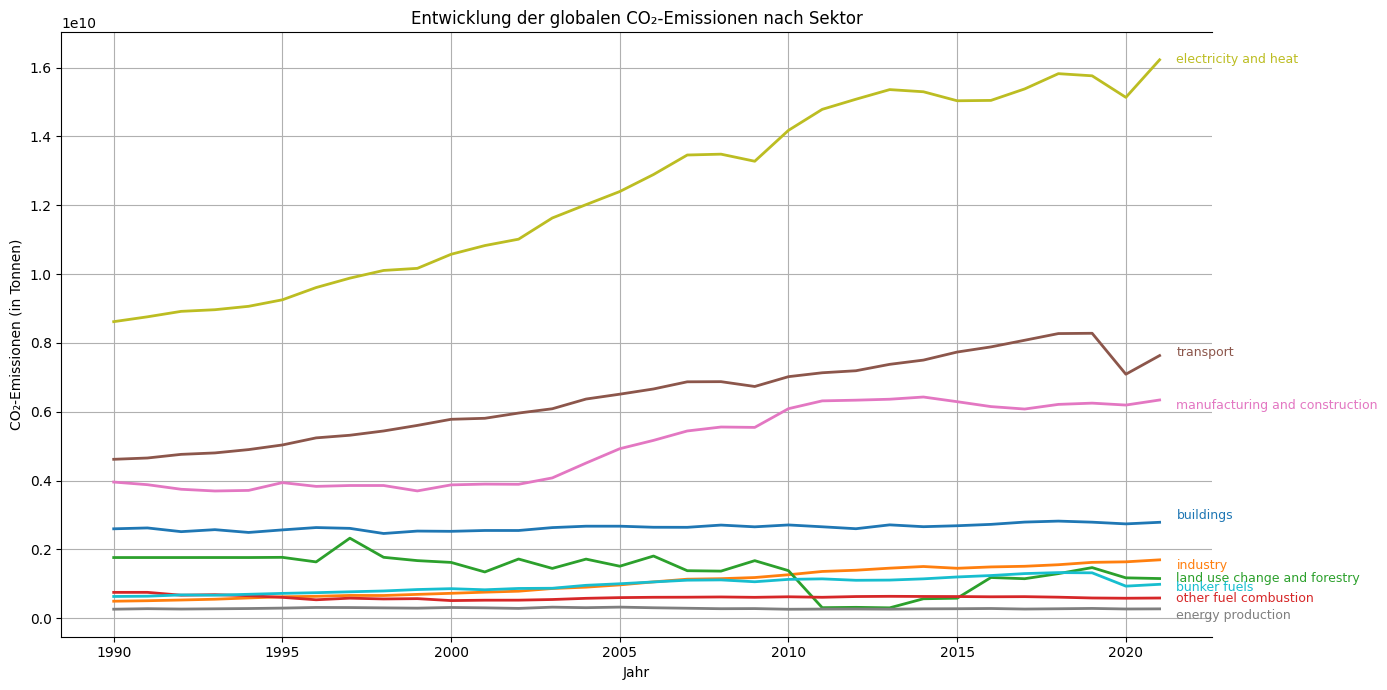

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np


df = pd.read_csv("data/co-emissions-by-sector.csv")


df_world = df[df["Entity"] == "World"].sort_values("Year")


emission_cols = [col for col in df.columns if "Carbon dioxide emissions" in col or "Fugitive emissions" in col]

plt.figure(figsize=(14, 7))
colors = cm.tab10(np.linspace(0, 1, len(emission_cols)))
last_values = {}

for i, (col, color) in enumerate(zip(emission_cols, colors)):
    if df_world[col].notna().any():
        label = col.replace("Carbon dioxide emissions from ", "").replace("Fugitive emissions of carbon dioxide from ", "")
        plt.plot(df_world["Year"], df_world[col], color=color, linewidth=2)
        last_values[label] = {
            "x": df_world["Year"].values[-1],
            "y": df_world[col].values[-1],
            "color": color,
            "offset": 0  
        }


custom_offsets = {
    "electricity and heat": 0,
    "transport": 1e8,
    "manufacturing and construction": -1.5e8,
    "buildings": 2e8,
    "industry": -1.5e8,
    "land use change and forestry": 0,
    "bunker fuels": -1e8,
    "other fuel combustion": -3,
    "energy production": -2e8
}


for label in last_values:
    if label in custom_offsets:
        last_values[label]["offset"] = custom_offsets[label]


for label, info in last_values.items():
    plt.text(info["x"] + 0.5, info["y"] + info["offset"], label,
             fontsize=9, color=info["color"], va='center')


plt.title("Entwicklung der globalen CO₂-Emissionen nach Sektor")
plt.xlabel("Jahr")
plt.ylabel("CO₂-Emissionen (in Tonnen)")
plt.grid(True)
plt.tight_layout()
plt.gca().spines['right'].set_visible(False)
plt.show()


/tmp/ipykernel_114102/1579860945.py:6: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv("sea_level_data.csv", comment="H", delim_whitespace=True, header=None)


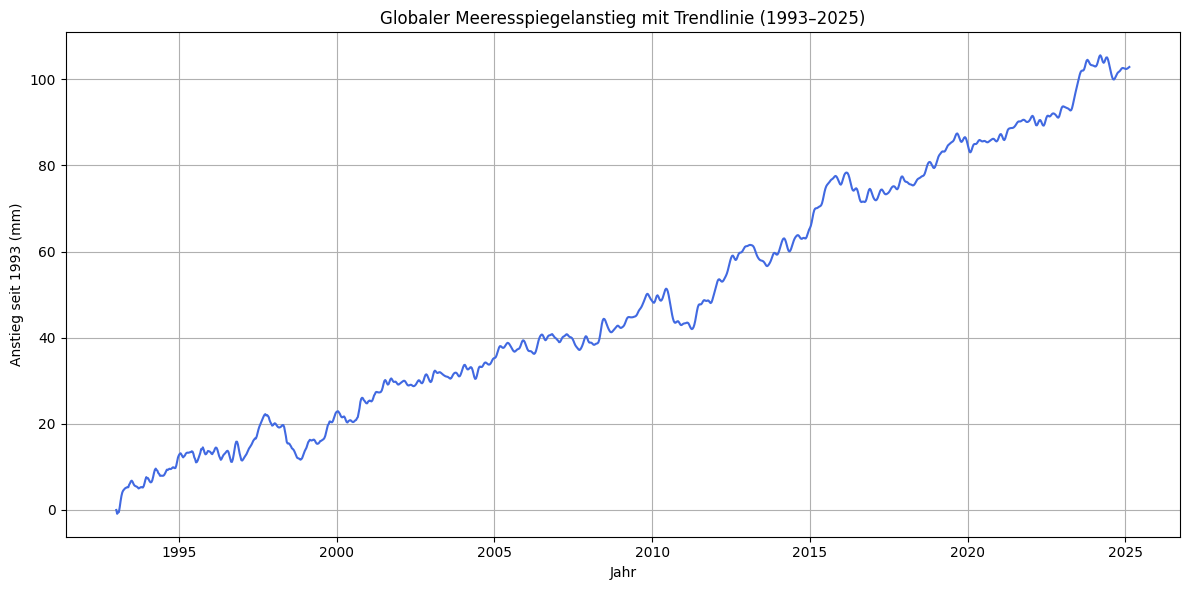

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


df = pd.read_csv("data/sea_level_data.csv", comment="H", delim_whitespace=True, header=None)
df_sea = df[[2, 12]].copy()
df_sea.columns = ["Year", "GMSL_mm"]


start_level = df_sea["GMSL_mm"].iloc[0]
df_sea["Relative_Anstieg_mm"] = df_sea["GMSL_mm"] - start_level


z = np.polyfit(df_sea["Year"], df_sea["Relative_Anstieg_mm"], 1)
p = np.poly1d(z)


plt.figure(figsize=(12, 6))
plt.plot(df_sea["Year"], df_sea["Relative_Anstieg_mm"], color="royalblue", label="Relativer Anstieg seit 1993")
plt.title("Globaler Meeresspiegelanstieg mit Trendlinie (1993–2025)")
plt.xlabel("Jahr")
plt.ylabel("Anstieg seit 1993 (mm)")
plt.grid(True)
plt.tight_layout()
plt.show()


/tmp/ipykernel_114102/1063084681.py:6: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv("sea_level_data.csv", comment="H", delim_whitespace=True, header=None)


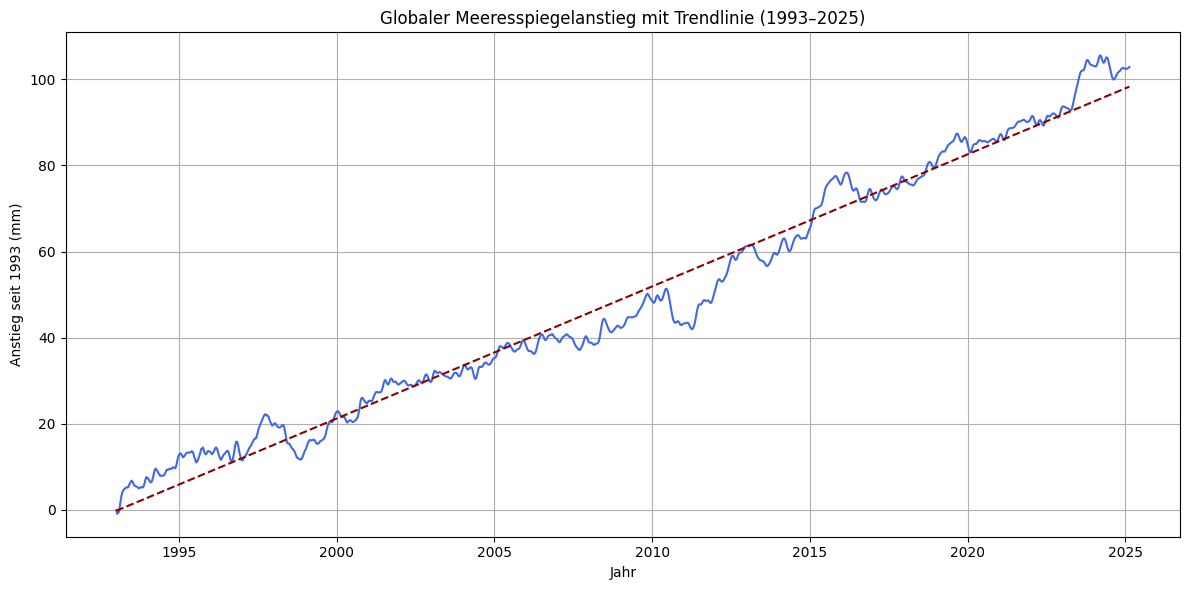

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


df = pd.read_csv("data/sea_level_data.csv", comment="H", delim_whitespace=True, header=None)
df_sea = df[[2, 12]].copy()
df_sea.columns = ["Year", "GMSL_mm"]


start_level = df_sea["GMSL_mm"].iloc[0]
df_sea["Relative_Anstieg_mm"] = df_sea["GMSL_mm"] - start_level


z = np.polyfit(df_sea["Year"], df_sea["Relative_Anstieg_mm"], 1)
p = np.poly1d(z)


plt.figure(figsize=(12, 6))
plt.plot(df_sea["Year"], df_sea["Relative_Anstieg_mm"], color="royalblue", label="Relativer Anstieg seit 1993")
plt.plot(df_sea["Year"], p(df_sea["Year"]), "--", color="darkred", label=f"Trend: {z[0]:.2f} mm/Jahr")
plt.title("Globaler Meeresspiegelanstieg mit Trendlinie (1993–2025)")
plt.xlabel("Jahr")
plt.ylabel("Anstieg seit 1993 (mm)")
plt.grid(True)
plt.tight_layout()
plt.show()


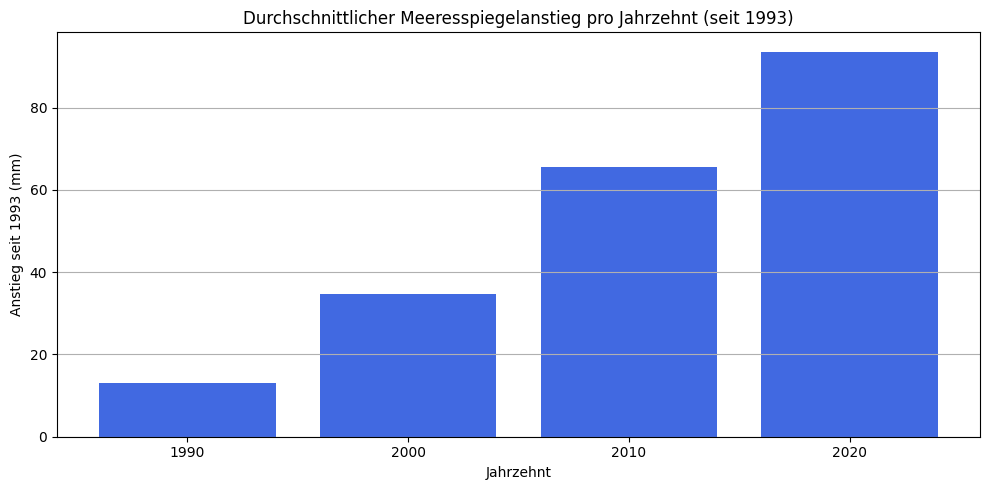

In [14]:

df_sea["Decade"] = (df_sea["Year"] // 10) * 10
decadal_avg = df_sea.groupby("Decade")["Relative_Anstieg_mm"].mean().reset_index()


plt.figure(figsize=(10, 5))
plt.bar(decadal_avg["Decade"].astype(int).astype(str), decadal_avg["Relative_Anstieg_mm"], color="royalblue")
plt.title("Durchschnittlicher Meeresspiegelanstieg pro Jahrzehnt (seit 1993)")
plt.xlabel("Jahrzehnt")
plt.ylabel("Anstieg seit 1993 (mm)")
plt.grid(axis="y")
plt.tight_layout()
plt.show()


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


arktis_df = pd.read_csv("data/N_09_extent_v3.0.csv", header=None)
antarktis_df = pd.read_csv("data/S_09_extent_v3.0.csv", header=None)


columns = ["Year", "Month", "Source", "Region", "Extent", "Area"]
arktis_df.columns = antarktis_df.columns = columns


arktis = arktis_df[["Year", "Extent"]].dropna()
antarktis = antarktis_df[["Year", "Extent"]].dropna()

arktis["Year"] = pd.to_numeric(arktis["Year"], errors="coerce")
arktis["Extent"] = pd.to_numeric(arktis["Extent"], errors="coerce")
antarktis["Year"] = pd.to_numeric(antarktis["Year"], errors="coerce")
antarktis["Extent"] = pd.to_numeric(antarktis["Extent"], errors="coerce")


arktis = arktis.groupby("Year").mean().reset_index()
antarktis = antarktis.groupby("Year").mean().reset_index()


arktis_trend = np.poly1d(np.polyfit(arktis["Year"], arktis["Extent"], 1))
antarktis_trend = np.poly1d(np.polyfit(antarktis["Year"], antarktis["Extent"], 1))


fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(arktis["Year"], arktis["Extent"], label="Arktis", color="royalblue")
ax.plot(antarktis["Year"], antarktis["Extent"], label="Antarktis", color="seagreen")
ax.plot(arktis["Year"], arktis_trend(arktis["Year"]), linestyle="--", color="blue")
ax.plot(antarktis["Year"], antarktis_trend(antarktis["Year"]), linestyle="--", color="green")


ax.text(arktis["Year"].iloc[-1] + 0.5, arktis["Extent"].iloc[-1], "Arktis", color="royalblue", fontsize=10)
ax.text(antarktis["Year"].iloc[-1] + 0.5, antarktis["Extent"].iloc[-1], "Antarktis", color="seagreen", fontsize=10)


ax.set_title("Meereisausdehnung im September: Arktis vs. Antarktis (1979–2024)")
ax.set_xlabel("Jahr")
ax.set_ylabel("Eisfläche (Mio. km²)")
ax.grid(True)
ax.spines["right"].set_visible(False)  
ax.tick_params(right=False)
plt.tight_layout()
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: 'N_09_extent_v3.0.csv'

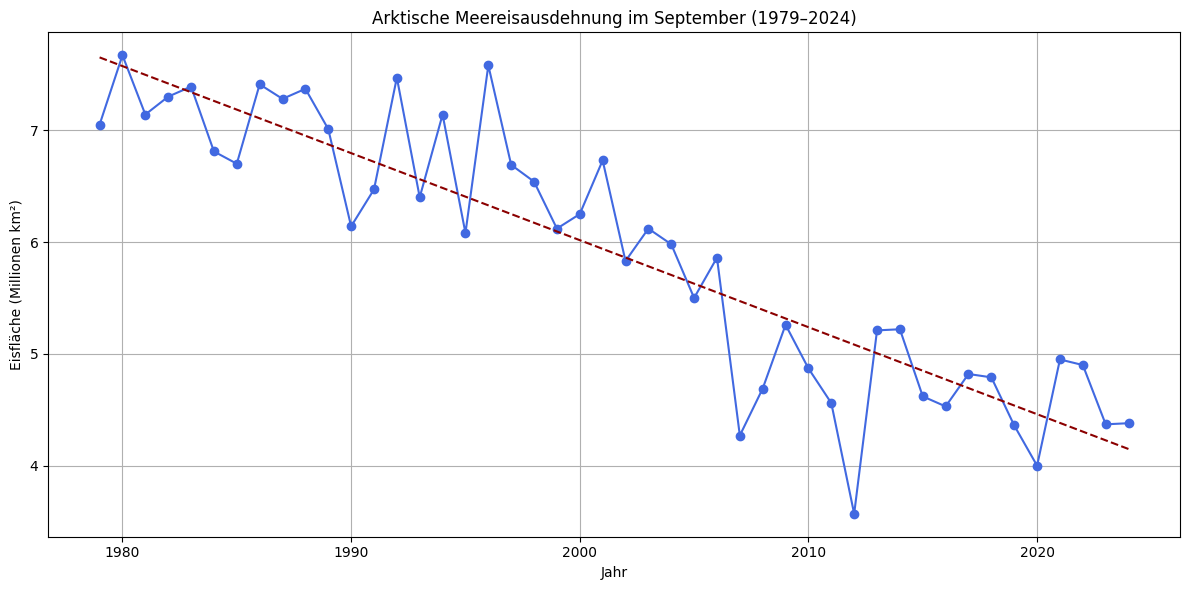

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


file_path = "N_09_extent_v3.0.csv"
df = pd.read_csv(file_path, header=None)


df.columns = ["Year", "Month", "Source", "Region", "Extent", "Area"]


df = df[["Year", "Extent"]].copy()
df["Year"] = pd.to_numeric(df["Year"], errors='coerce')
df["Extent"] = pd.to_numeric(df["Extent"], errors='coerce')


import numpy as np

df = df.dropna(subset=["Year", "Extent"])

z = np.polyfit(df["Year"], df["Extent"], 1)
p = np.poly1d(z)


plt.figure(figsize=(12, 6))
plt.plot(df["Year"], df["Extent"], marker='o', linestyle='-', color='royalblue', label="Meereisausdehnung im September")
plt.plot(df["Year"], p(df["Year"]), linestyle='--', color='darkred', label=f"Trendlinie ({z[0]:.2f} Mio. km²/Jahr)")
plt.title("Arktische Meereisausdehnung im September (1979–2024)")
plt.xlabel("Jahr")
plt.ylabel("Eisfläche (Millionen km²)")
plt.grid(True)
plt.tight_layout()
plt.show()


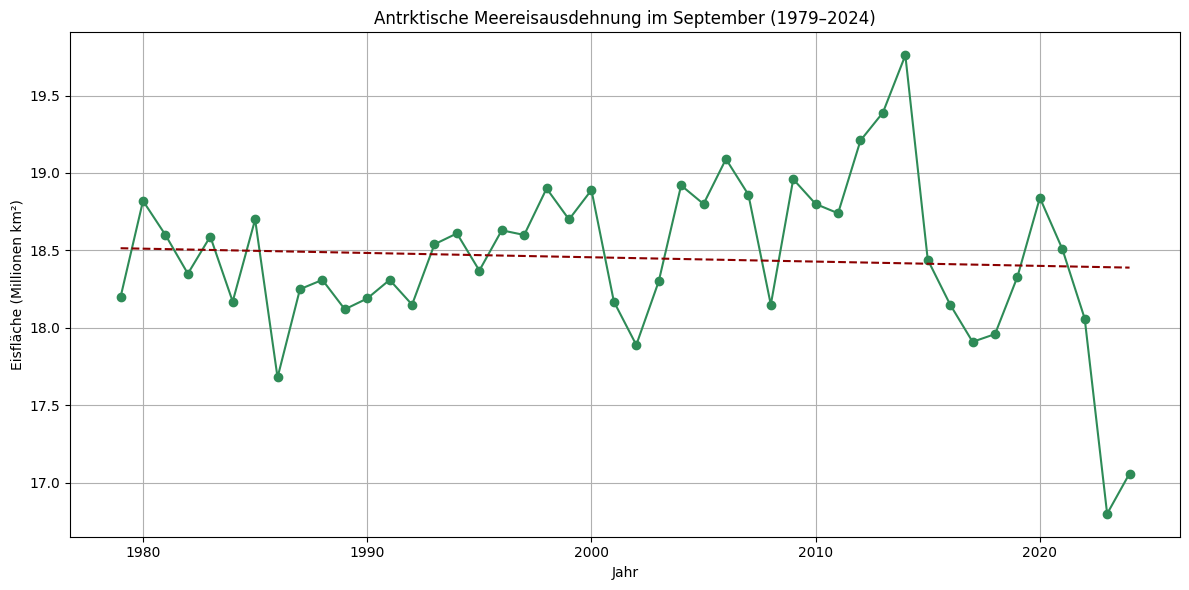

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


file_path = "S_09_extent_v3.0.csv"
df = pd.read_csv(file_path, header=None)


df.columns = ["Year", "Month", "Source", "Region", "Extent", "Area"]


df = df[["Year", "Extent"]].copy()
df["Year"] = pd.to_numeric(df["Year"], errors='coerce')
df["Extent"] = pd.to_numeric(df["Extent"], errors='coerce')


import numpy as np

df = df.dropna(subset=["Year", "Extent"])

z = np.polyfit(df["Year"], df["Extent"], 1)
p = np.poly1d(z)

plt.figure(figsize=(12, 6))
plt.plot(df["Year"], df["Extent"], marker='o', linestyle='-', color='seagreen', label="Meereisausdehnung im September")
plt.plot(df["Year"], p(df["Year"]), linestyle='--', color='darkred', label=f"Trendlinie ({z[0]:.2f} Mio. km²/Jahr)")
plt.title("Antrktische Meereisausdehnung im September (1979–2024)")
plt.xlabel("Jahr")
plt.ylabel("Eisfläche (Millionen km²)")
plt.grid(True)
plt.tight_layout()
plt.show()


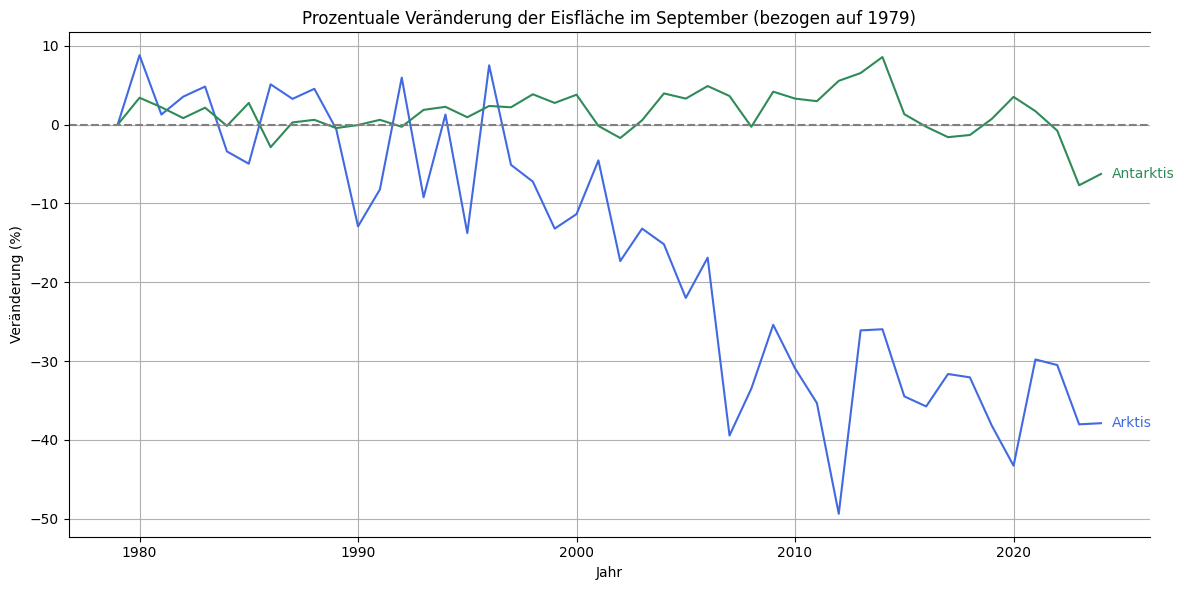

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


arktis_df = pd.read_csv("data/N_09_extent_v3.0.csv", header=None)
antarktis_df = pd.read_csv("data/S_09_extent_v3.0.csv", header=None)


columns = ["Year", "Month", "Source", "Region", "Extent", "Area"]
arktis_df.columns = antarktis_df.columns = columns


arktis = arktis_df[["Year", "Extent"]].dropna()
antarktis = antarktis_df[["Year", "Extent"]].dropna()


arktis["Year"] = pd.to_numeric(arktis["Year"], errors="coerce")
arktis["Extent"] = pd.to_numeric(arktis["Extent"], errors="coerce")
antarktis["Year"] = pd.to_numeric(antarktis["Year"], errors="coerce")
antarktis["Extent"] = pd.to_numeric(antarktis["Extent"], errors="coerce")

arktis = arktis.groupby("Year").mean().reset_index()
antarktis = antarktis.groupby("Year").mean().reset_index()

arktis_base = arktis.iloc[0]["Extent"]
antarktis_base = antarktis.iloc[0]["Extent"]
arktis["Change_%"] = (arktis["Extent"] - arktis_base) / arktis_base * 100
antarktis["Change_%"] = (antarktis["Extent"] - antarktis_base) / antarktis_base * 100

plt.figure(figsize=(12, 6))
plt.plot(arktis["Year"], arktis["Change_%"], color="royalblue")
plt.plot(antarktis["Year"], antarktis["Change_%"], color="seagreen")
plt.axhline(0, color='gray', linestyle='--')

plt.text(arktis["Year"].iloc[-1] + 0.5, arktis["Change_%"].iloc[-1], "Arktis", color="royalblue", va='center')
plt.text(antarktis["Year"].iloc[-1] + 0.5, antarktis["Change_%"].iloc[-1], "Antarktis", color="seagreen", va='center')

plt.title("Prozentuale Veränderung der Eisfläche im September (bezogen auf 1979)")
plt.xlabel("Jahr")
plt.ylabel("Veränderung (%)")
plt.grid(True)
plt.tight_layout()
plt.gca().spines['right'].set_visible(False)  
plt.show()


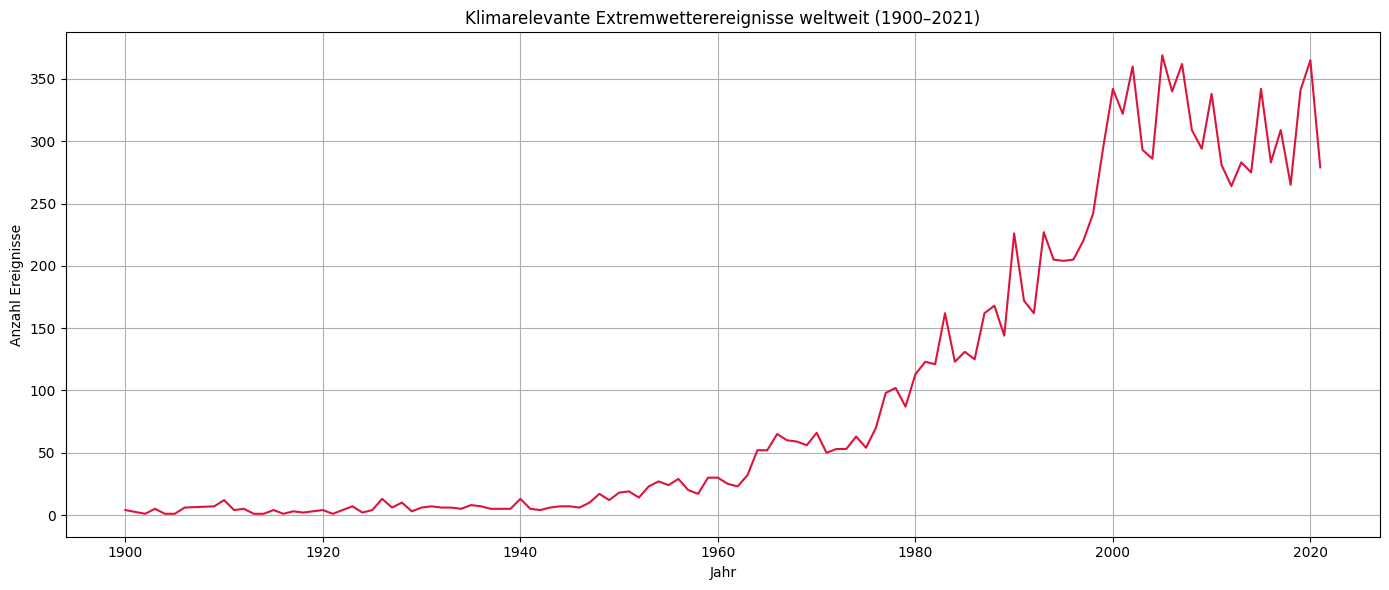

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/1900_2021_DISASTERS.xlsx - emdat data.csv")

klimarelevante_typen = [
    "Flood",              
    "Storm",              
    "Drought",            
    "Extreme temperature",
    "Wildfire",           
    "Landslide"           
]

df_klima = df[df["Disaster Type"].isin(klimarelevante_typen)]

events_per_year = df_klima.groupby("Year").size()

plt.figure(figsize=(14, 6))
plt.plot(events_per_year.index, events_per_year.values, color="crimson")
plt.title("Klimarelevante Extremwetterereignisse weltweit (1900–2021)")
plt.xlabel("Jahr")
plt.ylabel("Anzahl Ereignisse")
plt.grid(True)
plt.tight_layout()
plt.show()


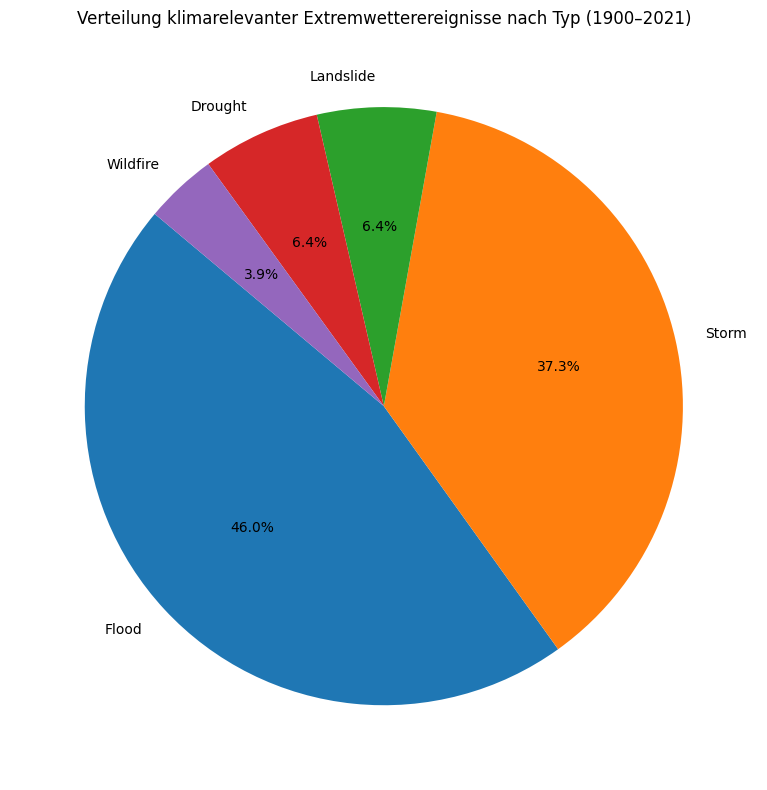

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/1900_2021_DISASTERS.xlsx - emdat data.csv")

klimarelevante_typen = [
    "Flood",
    "Storm",
    "Drought",
    "Extreme temperature",
    "Wildfire",
    "Landslide"
]

df_klima = df[df["Disaster Type"].isin(klimarelevante_typen)]

event_type_counts = df_klima["Disaster Type"].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(event_type_counts,
        labels=event_type_counts.index,
        autopct="%1.1f%%",
        startangle=140)
plt.title("Verteilung klimarelevanter Extremwetterereignisse nach Typ (1900–2021)")
plt.tight_layout()
plt.show()


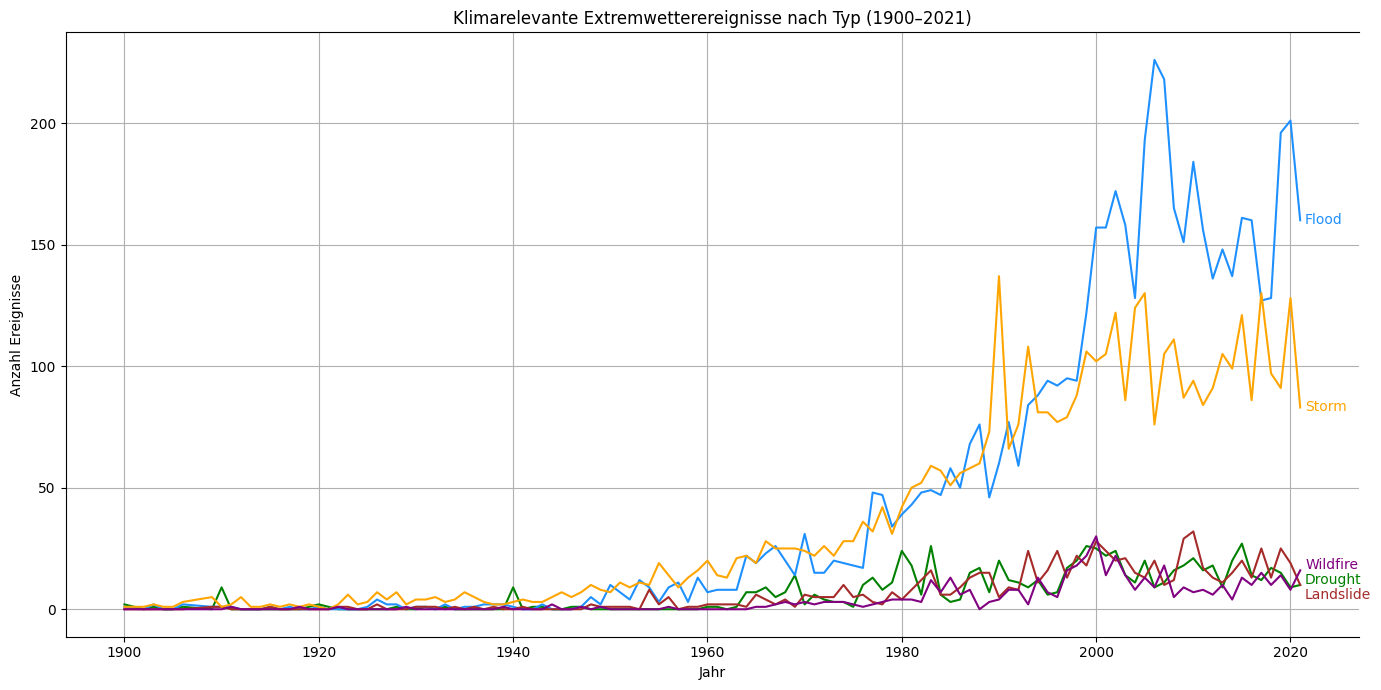

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/1900_2021_DISASTERS.xlsx - emdat data.csv")

farben = {
    "Flood": "dodgerblue",
    "Storm": "orange",
    "Drought": "green",
    "Extreme temperature": "red",
    "Wildfire": "purple",
    "Landslide": "brown"
}

events_by_year_type = df_klima.groupby(["Year", "Disaster Type"]).size().unstack(fill_value=0)

plt.figure(figsize=(14, 7))

label_offsets = {
    "Flood": 0,
    "Storm": 0,
    "Drought": 2,
    "Extreme temperature": -2,
    "Wildfire": 2,
    "Landslide": -4
}

for typ in events_by_year_type.columns:
    plt.plot(events_by_year_type.index, events_by_year_type[typ],
             label=typ, color=farben.get(typ, "gray"))

    last_year = events_by_year_type.index[-1]
    last_value = events_by_year_type[typ].iloc[-1]
    offset = label_offsets.get(typ, 0)

    plt.text(last_year + 0.5, last_value + offset, typ,
             color=farben.get(typ, "gray"), fontsize=10,
             va='center')

plt.title("Klimarelevante Extremwetterereignisse nach Typ (1900–2021)")
plt.xlabel("Jahr")
plt.ylabel("Anzahl Ereignisse")
plt.grid(True)

plt.gca().spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


/tmp/ipykernel_104681/4064211181.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_malaria = df.groupby("temp_group")["malaria_cases"].median().reset_index()


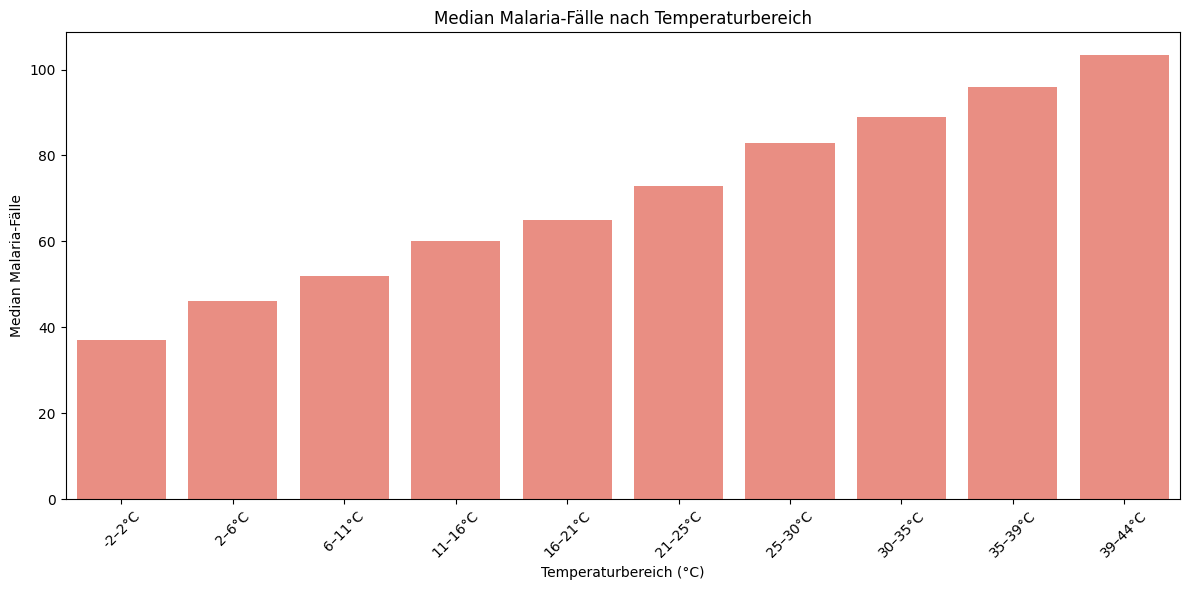

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("data/climate_disease_dataset.csv")

bins = pd.cut(df["avg_temp_c"], bins=10)
rounded_labels = [f"{int(interval.left)}–{int(interval.right)}°C" for interval in bins.cat.categories]
df["temp_group"] = pd.cut(df["avg_temp_c"], bins=10, labels=rounded_labels)

grouped_malaria = df.groupby("temp_group")["malaria_cases"].median().reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(data=grouped_malaria, x="temp_group", y="malaria_cases", color="salmon")
plt.title("Median Malaria-Fälle nach Temperaturbereich")
plt.xlabel("Temperaturbereich (°C)")
plt.ylabel("Median Malaria-Fälle")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
